
# U.S. Economic Analysis: Unemployment and Economic Indicators (2000–2024)

**Author:** Eliane Tapia

## Project Overview

This project examines the relationship between U.S. unemployment and selected economic indicators from 2000 to 2024 using Python and World Bank data.

The analysis explores how GDP growth, inflation, and previous year's unemployment relate to current unemployment through exploratory data analysis, visualization, and regression modeling.

## Research Questions

1. How has U.S. unemployment changed between 2000 and 2024?
2. What relationships exist between unemployment, GDP growth, inflation, and GDP per capita?
3. Can economic indicators help explain changes in unemployment?
4. Does incorporating previous year's unemployment improve model performance?

## Tools and Technologies

- Python
- Jupyter Notebook
- pandas
- NumPy
- Matplotlib
- scikit-learn
- statsmodels
- World Bank API

## Dataset

Annual U.S. economic indicators covering 2000–2024, retrieved from the World Bank API.


In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Collection

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
indicators = {
    "Unemployment": "SL.UEM.TOTL.NE.ZS",
    "GDPGrowth": "NY.GDP.MKTP.KD.ZG",
    "Inflation": "FP.CPI.TOTL.ZG",
    "GDPPerCapita": "NY.GDP.PCAP.KD"}

In [4]:
url = "https://api.worldbank.org/v2/country/USA/indicator/SL.UEM.TOTL.NE.ZS"

params = {
    "format": "json",
    "date": "2000:2024",
    "per_page": 100}

response = requests.get(url, params=params)

data = response.json()

In [5]:
unemployment =pd.DataFrame(data[1])
unemployment.head()

,indicator,country,countryiso3code,date,value,unit,obs_status,decimal
0,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2024,4.022,,,1
1,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2023,3.638,,,1
2,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2022,3.650,,,1
3,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2021,5.349,,,1
4,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2020,8.055,,,1


In [6]:
unemployment.columns
unemployment.head()

,indicator,country,countryiso3code,date,value,unit,obs_status,decimal
0,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2024,4.022,,,1
1,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2023,3.638,,,1
2,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2022,3.650,,,1
3,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2021,5.349,,,1
4,"{'id': 'SL.UEM.TOTL.NE.ZS', 'value': 'Unemploy...","{'id': 'US', 'value': 'United States'}",USA,2020,8.055,,,1


In [7]:
unemployment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   indicator        25 non-null     object 
 1   country          25 non-null     object 
 2   countryiso3code  25 non-null     object 
 3   date             25 non-null     object 
 4   value            25 non-null     float64
 5   unit             25 non-null     object 
 6   obs_status       25 non-null     object 
 7   decimal          25 non-null     int64  
dtypes: float64(1), int64(1), object(6)
memory usage: 1.7+ KB


In [8]:
unemployment.isnull().sum()

indicator          0
country            0
countryiso3code    0
date               0
value              0
unit               0
obs_status         0
decimal            0
dtype: int64

In [9]:
unemployment.describe()

,value,decimal
count,25.000000,25.0
mean,5.694720,1.0
std,1.836783,0.0
min,3.638000,1.0
25%,4.355000,1.0
50%,5.280000,1.0
75%,6.168000,1.0
max,9.633000,1.0


In [10]:
def get_world_bank_data(country, indicator, start_year, end_year):
    
    url = f"https://api.worldbank.org/v2/country/{country}/indicator/{indicator}"
    
    params = {
        "format": "json",
        "date": f"{start_year}:{end_year}",
        "per_page": 100}
    
    response = requests.get(url, params=params)
    data = response.json()
    
    df = pd.DataFrame(data[1])
    
    df = df[["date", "value"]]
    df.columns = ["Year", indicator]
    
    df["Year"] = pd.to_numeric(df["Year"])
    df[indicator] = pd.to_numeric(df[indicator])
    
    return df

In [11]:
unemployment = get_world_bank_data(
    "USA",
    "SL.UEM.TOTL.NE.ZS",
    2000,
    2024)

In [12]:
gdp_growth = get_world_bank_data(
    "USA",
    "NY.GDP.MKTP.KD.ZG",
    2000,
    2024)

In [13]:
inflation = get_world_bank_data(
    "USA",
    "FP.CPI.TOTL.ZG",
    2000,
    2024)

In [14]:
inflation.head()

,Year,FP.CPI.TOTL.ZG
0,2024,2.949525
1,2023,4.116338
2,2022,8.002800
3,2021,4.697859
4,2020,1.233584


In [15]:
gdp_per_capita = get_world_bank_data(
    "USA",
    "NY.GDP.PCAP.KD",
    2000,
    2024)

## Data Cleaning

In [16]:
df = unemployment.merge(gdp_growth,on="Year")
df = df.merge(inflation, on="Year")
df = df.merge ( gdp_per_capita, on="Year")

In [17]:
df.head()

,Year,SL.UEM.TOTL.NE.ZS,NY.GDP.MKTP.KD.ZG,FP.CPI.TOTL.ZG,NY.GDP.PCAP.KD
0,2024,4.022,2.793187,2.949525,66856.513170
1,2023,3.638,2.934363,4.116338,65667.281580
2,2022,3.650,2.524214,8.002800,64322.233282
3,2021,5.349,6.152022,4.697859,63096.785615
4,2020,8.055,-2.081376,1.233584,59533.609024


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 25 entries, 0 to 24
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               25 non-null     int64  
 1   SL.UEM.TOTL.NE.ZS  25 non-null     float64
 2   NY.GDP.MKTP.KD.ZG  25 non-null     float64
 3   FP.CPI.TOTL.ZG     25 non-null     float64
 4   NY.GDP.PCAP.KD     25 non-null     float64
dtypes: float64(4), int64(1)
memory usage: 1.2 KB


In [19]:
df.shape

(25, 5)

In [20]:
df = df.rename(columns ={
    "SL.UEM.TOTL.NE.ZS": "Unemployment",
    "NY.GDP.MKTP.KD.ZG": "GDP_Growth",
    "FP.CPI.TOTL.ZG": "Inflation",
    "NY.GDP.PCAP.KD": "GDP_per_Capita"})

df.head()

    

,Year,Unemployment,GDP_Growth,Inflation,GDP_per_Capita
0,2024,4.022,2.793187,2.949525,66856.513170
1,2023,3.638,2.934363,4.116338,65667.281580
2,2022,3.650,2.524214,8.002800,64322.233282
3,2021,5.349,6.152022,4.697859,63096.785615
4,2020,8.055,-2.081376,1.233584,59533.609024


In [21]:
df.isnull().sum()

Year              0
Unemployment      0
GDP_Growth        0
Inflation         0
GDP_per_Capita    0
dtype: int64

In [22]:
df=df.sort_values("Year").reset_index(drop="True")
df.head()

,Year,Unemployment,GDP_Growth,Inflation,GDP_per_Capita
0,2000,3.992,4.077586,3.376857,48616.254628
1,2001,4.731,0.955538,2.826171,48597.424612
2,2002,5.783,1.700447,1.586032,48967.366122
3,2003,5.989,2.795606,2.270095,49905.523308
4,2004,5.529,3.847772,2.677237,51348.347339


In [23]:
df.tail()

,Year,Unemployment,GDP_Growth,Inflation,GDP_per_Capita
20,2020,8.055,-2.081376,1.233584,59533.609024
21,2021,5.349,6.152022,4.697859,63096.785615
22,2022,3.650,2.524214,8.002800,64322.233282
23,2023,3.638,2.934363,4.116338,65667.281580
24,2024,4.022,2.793187,2.949525,66856.513170


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year            25 non-null     int64  
 1   Unemployment    25 non-null     float64
 2   GDP_Growth      25 non-null     float64
 3   Inflation       25 non-null     float64
 4   GDP_per_Capita  25 non-null     float64
dtypes: float64(4), int64(1)
memory usage: 1.1 KB


## Exploratory Data Analysis

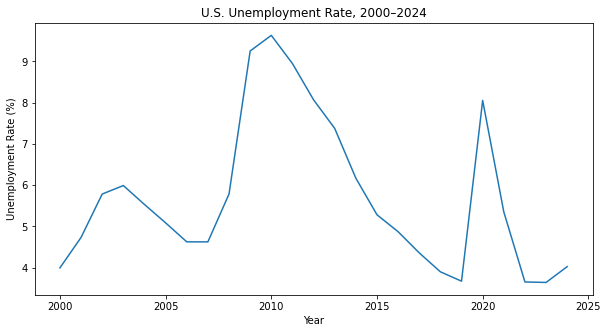

In [25]:
df[["Year","Unemployment"]]
plt.figure(figsize=(10, 5))

plt.plot(df["Year"], df["Unemployment"])

plt.title("U.S. Unemployment Rate, 2000–2024")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")

plt.show()

In [26]:
df.describe()

,Year,Unemployment,GDP_Growth,Inflation,GDP_per_Capita
count,25.000000,25.000000,25.000000,25.000000,25.000000
mean,2012.000000,5.694720,2.218868,2.576392,55875.308332
std,7.359801,1.836783,1.765360,1.627764,5306.406180
min,2000.000000,3.638000,-2.576500,-0.355546,48597.424612
25%,2006.000000,4.355000,1.819451,1.622223,52649.571306
50%,2012.000000,5.280000,2.524214,2.442583,54152.829267
75%,2018.000000,6.168000,2.934363,3.225944,59533.609024
max,2024.000000,9.633000,6.152022,8.002800,66856.513170


In [27]:
df[["Unemployment", "GDP_Growth","Inflation","GDP_per_Capita"]].describe()

,Unemployment,GDP_Growth,Inflation,GDP_per_Capita
count,25.000000,25.000000,25.000000,25.000000
mean,5.694720,2.218868,2.576392,55875.308332
std,1.836783,1.765360,1.627764,5306.406180
min,3.638000,-2.576500,-0.355546,48597.424612
25%,4.355000,1.819451,1.622223,52649.571306
50%,5.280000,2.524214,2.442583,54152.829267
75%,6.168000,2.934363,3.225944,59533.609024
max,9.633000,6.152022,8.002800,66856.513170


In [28]:
correlation_matrix = df[["Unemployment", "GDP_Growth","Inflation","GDP_per_Capita"]].corr()
correlation_matrix

,Unemployment,GDP_Growth,Inflation,GDP_per_Capita
Unemployment,1.000000,-0.482532,-0.463121,-0.384652
GDP_Growth,-0.482532,1.000000,0.416438,0.184923
Inflation,-0.463121,0.416438,1.000000,0.357559
GDP_per_Capita,-0.384652,0.184923,0.357559,1.000000


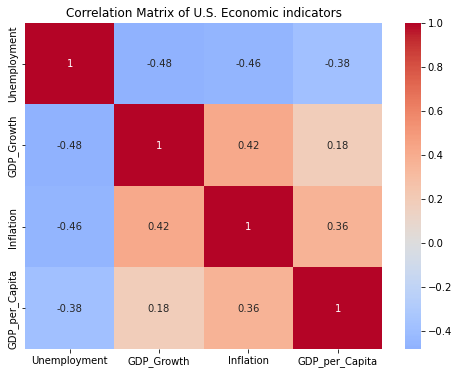

In [29]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix,
            annot=True,
            cmap= "coolwarm",
            center=0)
plt.title("Correlation Matrix of U.S. Economic indicators")
plt.show()

Unemployment & GDP growth: Moderate negative relationship
Unemployment & inflation: Moderate negative relationship
Unemployment & GDP per Capita: Weak to moderate negative relationship
GDP growth & inflation: Moderate positive relationship
GDP growth & GDP per Capita: Weak positive relationship
Inflation & GDP per Capita: Weak to moderate positive relationship

Between 2000 and 2024, year with higher GDP generally tended to have lower unemployment rates. Similarly, years with negative GDP growth had higher unemployment rates. A similar pattern can be seen with the relationship between unemployment and inflation. On years with positive GDP growth inflation rates were also positive, and when GDP growth was negative inflation rates were also negative.

## Data Visualization

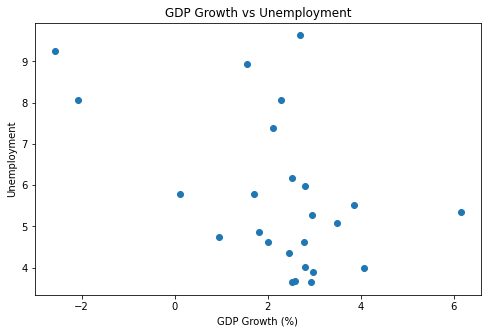

In [30]:
plt.figure(figsize=(8,5))
plt.scatter(df["GDP_Growth"], df["Unemployment"])
plt.title("GDP Growth vs Unemployment")
plt.xlabel("GDP Growth (%)")
plt.ylabel("Unemployment")
plt.show()

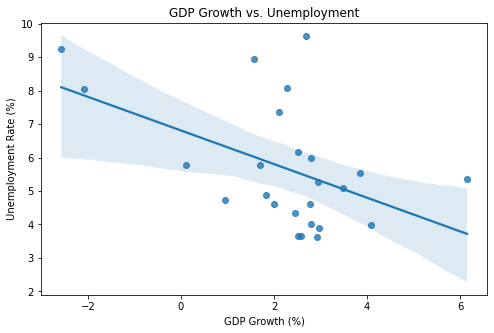

In [31]:
plt.figure(figsize=(8,5))

sns.regplot(x="GDP_Growth", 
            y= "Unemployment",
            data=df)
plt.title("GDP Growth vs. Unemployment")
plt.xlabel("GDP Growth (%)")
plt.ylabel("Unemployment Rate (%)")

plt.show()

U.S. data from 2000 - 2024 show a moderate negative association between GDP growth and unemployment, suggesting that stronger economic growth generally coincided with lower unemployment. 

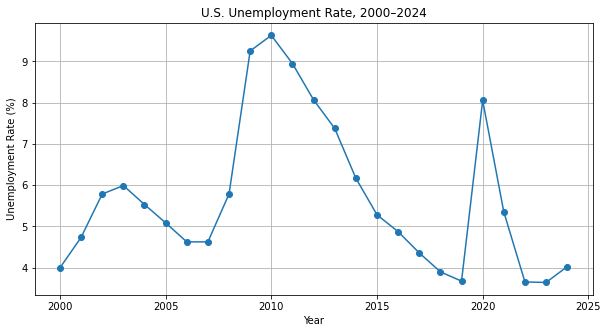

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["Year"],
    df["Unemployment"],
    marker="o")

plt.title("U.S. Unemployment Rate, 2000–2024")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.grid(True)

plt.show()

Unemployment increased during the early-2000's slowdown. At around 2008 we see unemployment ride sharply during the financial crisis, peaking around 2010. As the economy recovered, unemployment generally declined between 2011 and 2019. We see unemployment spike in 2020 during the COVID-19 pandemic. Finally unemployment fell substantially and remained relatively low between 2021-2024.

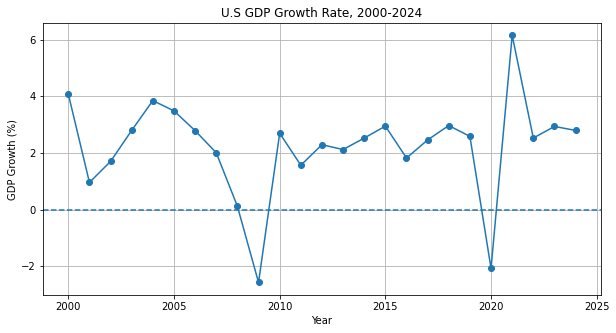

In [33]:
plt.figure(figsize=(10,5))
plt.plot( df["Year"],
          df ["GDP_Growth"],
          marker="o")
plt.title ("U.S GDP Growth Rate, 2000-2024")
plt.xlabel("Year")
plt.ylabel("GDP Growth (%)")
plt.axhline( y=0, linestyle="--")
plt.grid(True)

plt.show()

We see GDP fluctuate between 2001 and 2007, remaining positive. In 2008, we see the growth weakened sharply, with a substantial contraction in 2009 during the financial crisis. Fro, 2010 to 2019 the GDP returned to positive and fluctuated around 2-3%. In 2020 GDP contracted due to COVID-19. In 2021, the growth rebounded sharply and finally stabilizing during 2022 to 2024.

The graph illustrates how major economic shocks can produce sharp contractions followed by recoveries. 

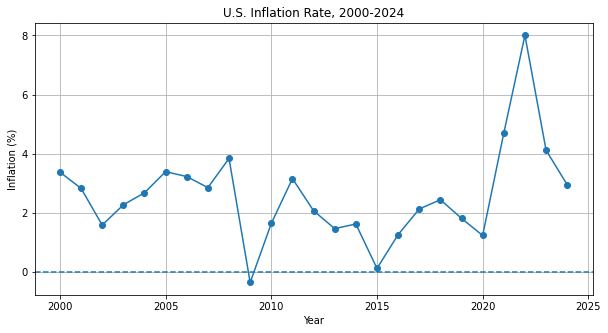

In [34]:
plt.figure(figsize=(10,5))
plt.plot(df["Year"],
         df["Inflation"],
         marker="o")
plt.title("U.S. Inflation Rate, 2000-2024")
plt.xlabel("Year")
plt.ylabel("Inflation (%)")
plt.axhline(y=0, linestyle="--")
plt.grid(True)

plt.show()

The graph shows us a slow down in inflation in 2008 after a period of inflation increase. We see relatively low inflation 2020 during the COVID-19 pandemic followed by a sharp increase in 2021 to 2022. Finally, we see a decline through 2024

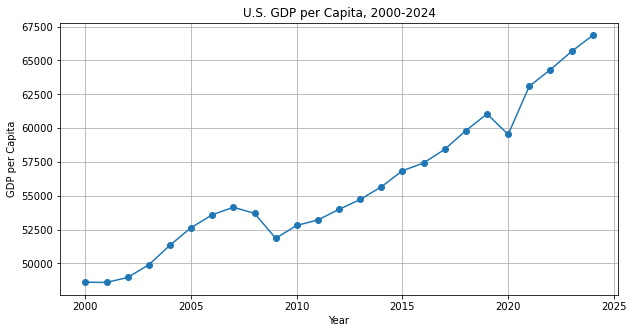

In [35]:
plt.figure(figsize=(10,5))
plt.plot(df["Year"],
         df["GDP_per_Capita"],
         marker="o")
plt.title("U.S. GDP per Capita, 2000-2024")
plt.xlabel("Year")
plt.ylabel("GDP per Capita")
plt.grid(True)

plt.show()

From 2000 to 2007 GDP per Capita increased steadily. It declined during the financial crisis in 2008, reaching it's lowest point during 2009. From 2010 to 2019, GDP per Capita generally increased as the economy expanded and fell again during the 2020 pandemic. in 2021 till 2024 we see GDP per Capita recover and reach it's highest level at around $66,857.

GDP per Capita increased substantially over this period, despite temporary setbacks during major economic disruptions.

## Simple Regression

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

X=df[["GDP_Growth"]]
y = df[["Unemployment"]]

model= LinearRegression()
model.fit(X,y)

y_pred=model.predict(X)

r2=r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))

print("Intercept:", model.intercept_)
print("GDP Growth Coefficient:",model.coef_[0])
print("R-squared:", r2)
print("RMSE:", rmse)

Intercept: [6.80871211]
GDP Growth Coefficient: [-0.50205414]
R-squared: 0.23283682082005552
RMSE: 1.5762945741899113


1. When GDP growth is 0%, the model predicts an unemployment rate of approximately 6.81% 
2. For every 1-percentage-point increase in GDP growth, the model predicts that unemployment will be approximately 0.50 percentage points lower,on average. 
3. GDP growth alone explains approximately 23.3% of the variation in unemployment in this model. This means that about 76.7% of the variation remains unexplained by this one-predictor model. Other economics factors and time related effects may matter.
4. The model's root mean squared error is about 1.58 percentage points of unemployment. This summarizes the size of its in-sample prediction errors, with larger errors penalized more heavily.

In [37]:
results= df[["Year", "Unemployment", "GDP_Growth"]].copy()
results["Predicted_Unemployment"] = model.predict(df[["GDP_Growth"]])
results["Residual"] = (results["Unemployment"]- results["Predicted_Unemployment"])
results.head(10)

,Year,Unemployment,GDP_Growth,Predicted_Unemployment,Residual
0,2000,3.992,4.077586,4.761543,-0.769543
1,2001,4.731,0.955538,6.328980,-1.597980
2,2002,5.783,1.700447,5.954995,-0.171995
3,2003,5.989,2.795606,5.405167,0.583833
4,2004,5.529,3.847772,4.876922,0.652078
5,2005,5.084,3.483550,5.059781,0.024219
6,2006,4.623,2.784540,5.410722,-0.787722
7,2007,4.622,2.003858,5.802667,-1.180667
8,2008,5.784,0.113587,6.751685,-0.967685
9,2009,9.254,-2.576500,8.102255,1.151745


We can see, for example, that on 2005 the model performed very well, with only a 0.024 residual, while in 2008 the model underestimated unemployment and in 2009 the model overestimated unemployment. These differences tell us that GDP growth cannot fully explain unemployment.

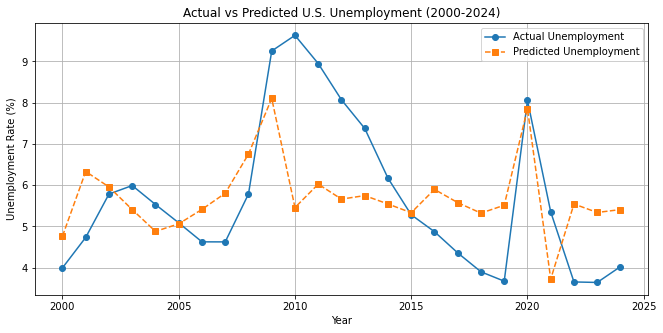

In [38]:
plt.figure(figsize=(11,5))
plt.plot(results["Year"],
         results["Unemployment"],
         marker="o",
         label="Actual Unemployment")

plt.plot(results["Year"],
         results["Predicted_Unemployment"],
         marker="s",
         linestyle="--",
         label= "Predicted Unemployment")
plt.title("Actual vs Predicted U.S. Unemployment (2000-2024)")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.grid(True)
plt.show()


The model performs reasonably well in years 2005 and 2020, where predicted unemployment rates are pretty close to the actual values. Between the years 2009 to 2013, actual unemployment was consistently higher than predicted. This suggests the model misses some of the persistence in unemployment following an economic downturn. The graph also shows that predicted unemployment fluctuates less than actual unemployment.

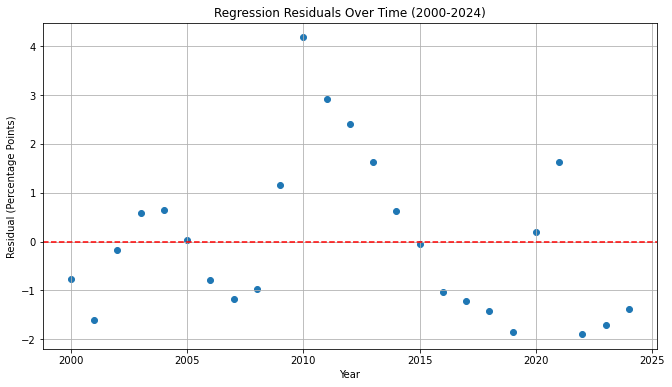

In [39]:
plt.figure(figsize=(11,6))
plt.scatter(results["Year"],results["Residual"])

plt.axhline(y=0,
            linestyle="--",
            color= "red")
plt.title("Regression Residuals Over Time (2000-2024)")
plt.xlabel("Year")
plt.ylabel("Residual (Percentage Points)")
plt.grid("True")
plt.show()

The model underestimated unemployment during the 2010-2013 period , as seen by the large positive residuals shown during this period. Between 2016-2019 the model exhibits negative residuals meaning it overestimated unemployment. The model then continued to overestimate unemployment in the period between 2021-2024. The main conclusion we can draw is that GDP alone is insufficient to capture the changing relationship between economic conditions and unemployment.  

## Multiple Regression

In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

X_multi= df[["GDP_Growth", "Inflation"]]
y = df["Unemployment"]

model_multi= LinearRegression()
model_multi.fit(X_multi, y)

y_pred_multi= model_multi.predict(X_multi)

r2_multi = r2_score(y, y_pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y, y_pred_multi))

print("Intercept:", model_multi.intercept_)
print("GDP Growth Coefficient:", model_multi.coef_[0])
print("Inflation Coefficient:",model_multi.coef_[1])
print("R-squared:", r2_multi)
print("RMSE:", rmse_multi)

Intercept: 7.425891825224219
GDP Growth Coefficient: -0.3646230148674977
Inflation Coefficient: -0.3579118406286977
R-squared: 0.31599476202258714
RMSE: 1.4884121936775996


1. Holding inflation constant, a 1-percentage-point increase in GDP growth is associated with a predicted decrease of approximately 0.365-percentage-points in unemployment.
2. Holding GDP growth constant, a a 1-percentage-point increase in inflation is associated with a predicted decrease of approximately 0.358-percentage-points in unemployment.
3. The model now explains approximately 31.6% of the variation in unemployment, compared to 23.3% in the simple regression model.
4. The prediction error decreased from approximately 1.576 to 1.488 percentage points

## Model Comparison

In [41]:
model_comparison = pd.DataFrame({"Model": ["Simple Regression","Multiple Regression"],
                                 "Predictors":["GDP Growth", "GDP Growth + Inflation"],
                                 "R_squared": [r2,r2_multi],
                                 "RMSE": [rmse, rmse_multi]})
model_comparison

,Model,Predictors,R_squared,RMSE
0,Simple Regression,GDP Growth,0.232837,1.576295
1,Multiple Regression,GDP Growth + Inflation,0.315995,1.488412


## Residual Analysis

In [42]:
results_multi= df[["Year", "Unemployment"]].copy()
results_multi["Predicted_Unemployment"] = y_pred_multi

results_multi["Residual"] =(results_multi["Unemployment"]-results_multi["Predicted_Unemployment"])

results_multi.head(10)

,Year,Unemployment,Predicted_Unemployment,Residual
0,2000,3.992,4.730493,-0.738493
1,2001,4.731,6.065960,-1.334960
2,2002,5.783,6.238210,-0.455210
3,2003,5.989,5.594056,0.394944
4,2004,5.529,5.064691,0.464309
5,2005,5.084,4.941405,0.142595
6,2006,4.623,5.255981,-0.632981
7,2007,4.622,5.674234,-1.052234
8,2008,5.784,6.010416,-0.226416
9,2009,9.254,8.492597,0.761403


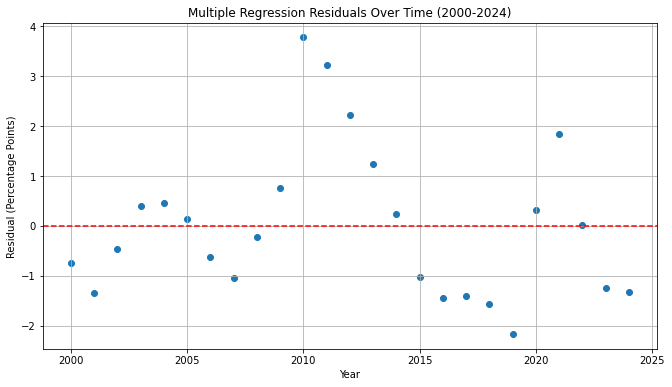

In [43]:
plt.figure(figsize=(11,6))
plt.scatter(results_multi["Year"], results_multi["Residual"])

plt.axhline( y=0, linestyle ="--", color = "red")

plt.title("Multiple Regression Residuals Over Time (2000-2024)")
plt.xlabel("Year")
plt.ylabel("Residual (Percentage Points)")
plt.grid("True")
plt.show()

The model stills underestimates unemployment between 2010 and 2013, especially around 2010-2012, where we see strongly positive residuals. The residuals then remain consistently negative from 2016 until 2024, overestimating unemployment and failing to capture labor market conditions post-pandemic. In terms of in-sample metrics, adding inflation improved the model by increasing R- squared from 0.233 to 0.316 and decreasing RMSE from 1.576 to 1.488, however, adding inflation alone did not resolve the models limitations. 

## Multicollinearity

In [44]:
predictor_corr =df[["GDP_Growth","Inflation"]].corr()
predictor_corr

,GDP_Growth,Inflation
GDP_Growth,1.000000,0.416438
Inflation,0.416438,1.000000


In [45]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [46]:
X_vif =df[["GDP_Growth", "Inflation"]]
X_vif_constant = sm.add_constant(X_vif)

vif_data = pd.DataFrame()

vif_data["VIF"] = [variance_inflation_factor(X_vif_constant.values, i)
                   for i in range(X_vif_constant.shape[1])]
vif_data

,VIF
0,4.059876
1,1.209806
2,1.209806


The correlation between inflation and GDP growth is 0.416438 indicating a moderate positive correlation. This shows that although the two are related, the relationship is not strong enough to worry about including both in the same regression model. The variance inflation factors for both GDP growth and inflation are close to 1, which indicates that multicollinearity is not a significant concern in this model. Since the two are not excessively correlated we can retain both variables as independent.  

## Model Validation

In [47]:
from sklearn.model_selection import train_test_split

X= df[["GDP_Growth", "Inflation"]]
y = df[["Unemployment"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 5, shuffle = False)

print("Training period:")
print(df.loc[X_train.index, "Year"].min(), "to", df.loc[X_train.index,"Year"].max())

print("\nTesting period:")
print(df.loc[X_test.index,"Year"].min(), "to", df.loc[X_test.index, "Year"].max())

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

Training period:
2000 to 2019

Testing period:
2020 to 2024

Training observations: 20
Testing observations: 5


In [48]:
model_test = LinearRegression()

model_test.fit(X_train, y_train)

y_test_pred = model_test.predict(X_test)
print("Training complete!")

Training complete!


In [49]:
test_r2= r2_score(y_test, y_test_pred)
test_rmse =np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Testing R-squared:", test_r2)
print("Testing RMSE:", test_rmse)

Testing R-squared: 0.4214778109927888
Testing RMSE: 1.2760290354446169


In [50]:
print("Year shape:", df.loc[X_test.index, "Year"].values.shape)
print("Actual shape:", y_test.values.shape)
print("Predicted shape:", y_test_pred.shape)

Year shape: (5,)
Actual shape: (5, 1)
Predicted shape: (5, 1)


In [51]:
validation_results = pd.DataFrame({ "Year": df.loc[X_test.index, "Year"].values,
                                    "Actual_Unemployment": np.asarray(y_test).ravel(),
                                    "Predicted_Unemployment": np.asarray(y_test_pred).ravel()})
validation_results["Residual"]=(validation_results["Actual_Unemployment"]-validation_results["Predicted_Unemployment"])
validation_results

,Year,Actual_Unemployment,Predicted_Unemployment,Residual
0,2020,8.055,8.218853,-0.163853
1,2021,5.349,3.111439,2.237561
2,2022,3.650,3.687999,-0.037999
3,2023,3.638,4.839862,-1.201862
4,2024,4.022,5.311111,-1.289111


The model performed well in 2020 and 2022, but it underestimated unemployment in 2021 while overestimating in 2023 and 2024. This suggest the relationship between GDP growth, unemployment, and inflation may have changed over time, but five test observations are too few to draw a strong conclusion.

### Model Validation Conclusion

The multiple linear regression model was trained using data from 2000–2019 and tested on unseen data from 2020–2024. The model achieved a test R-squared of 0.4215 and a test RMSE of 1.2760 percentage points. This indicates that the model explained approximately 42.15% of the variation in unemployment during the test period. The test RMSE was lower than the training RMSE of 1.4884, suggesting reasonable predictive performance on this particular test set. However, the test set contains only five observations, so the results should be interpreted cautiously. Overall, the model provides a useful starting point, but additional predictors may improve its ability to explain unemployment.

## Model Improvement

In [52]:
X_improved = df[["GDP_Growth", "Inflation", "GDP_per_Capita"]]
y = df["Unemployment"]

X_train_improved=X_improved.iloc[:-5]
X_test_improved = X_improved.iloc[-5:]
y_train_improved = y.iloc[:-5]
y_test_improved = y.iloc[-5:]

model_improved =LinearRegression()
model_improved.fit(X_train_improved, y_train_improved) 
y_test_pred_improved = model_improved.predict(X_test_improved) 

print("Improved model training complete!")

Improved model training complete!


In [53]:
r2_improved = r2_score(y_test_improved, y_test_pred_improved)
rmse_improved = np.sqrt(mean_squared_error( y_test_improved,y_test_pred_improved))

print("Improved Testing R-Squared:",r2_improved)
print("Improved Testing RMSE:", rmse_improved)
                        

Improved Testing R-Squared: -0.6293254862626545
Improved Testing RMSE: 2.141432904993228


The improved model has a negative R-squared, meaning that it performed worse than previous models. Its RMSE increased from 1.270 to 2.1414, meaning its prediction errors became substantially larger. GDP per capita may be introducing a trend that the model learned from 2000-2019 but did not translate well into 2020-2024. With only 20 observations, adding another predictor can also make the model more sensitive to the training data.

In [54]:
model_validation_comparison = pd.DataFrame({ "Model": ["Original Model","Improved Model"],
                                             "Predictors":["GDP Growth + Inflation",
                                                           "GDP growth + Inflation + GDP per Capita"],
                                             "Test_R_squared": [ test_r2, r2_improved],
                                             "Test_RMSE": [test_rmse, rmse_improved]})
model_validation_comparison

,Model,Predictors,Test_R_squared,Test_RMSE
0,Original Model,GDP Growth + Inflation,0.421478,1.276029
1,Improved Model,GDP growth + Inflation + GDP per Capita,-0.629325,2.141433



### Model Improvement Findings

An additional predictor, GDP per capita, was introduced to evaluate whether it improved the multiple linear regression model. The original model, using GDP growth and inflation, achieved a test R-squared of 0.4215 and a test RMSE of 1.2760. After adding GDP per capita, the improved model achieved a test R-squared of -0.6293 and a test RMSE of 2.1414. These results indicate that adding GDP per capita reduced the model's predictive performance on the 2020–2024 test period. The additional predictor may have introduced a time-trend effect that did not generalize well to the test data. Therefore, the original two-predictor model is preferred over this three-predictor model based on test-set performance.

In [55]:
df_lagged = df.copy()
df_lagged["Previous_Unemployment"]= (df_lagged ["Unemployment"].shift(1))
df_lagged = df_lagged.dropna()
df_lagged[["Year", "Unemployment", "Previous_Unemployment"]].head(10)

,Year,Unemployment,Previous_Unemployment
1,2001,4.731,3.992
2,2002,5.783,4.731
3,2003,5.989,5.783
4,2004,5.529,5.989
5,2005,5.084,5.529
6,2006,4.623,5.084
7,2007,4.622,4.623
8,2008,5.784,4.622
9,2009,9.254,5.784
10,2010,9.633,9.254


In [56]:
X_lagged =df_lagged[["GDP_Growth", "Inflation", "Previous_Unemployment"]]
y_lagged = df_lagged ["Unemployment"]

train_mask = df_lagged["Year"]<=2019
test_mask = df_lagged ["Year"]>=2020

X_train_lagged = X_lagged.loc[train_mask]
X_test_lagged = X_lagged.loc[test_mask]

y_train_lagged = y_lagged.loc[train_mask]
y_test_lagged = y_lagged.loc[test_mask]

model_lagged = LinearRegression()
model_lagged.fit(X_train_lagged, y_train_lagged)

y_test_pred_lagged = model_lagged.predict(X_test_lagged)

print("Training complete!")
print("Training observations:", len(X_train_lagged))
print("Testing observations:", len(X_test_lagged))

Training complete!
Training observations: 19
Testing observations: 5


In [57]:
r2_lagged = r2_score(y_test_lagged, y_test_pred_lagged) 
rmse_lagged = np.sqrt(mean_squared_error(y_test_lagged, y_test_pred_lagged))

print("Lagged model testing R-squared:", r2_lagged)
print("Lagged model testing RMSE:", rmse_lagged)

Lagged model testing R-squared: 0.6946173509183633
Lagged model testing RMSE: 0.9270917690511071


The lagged model explains approximately 69.46% of the variation in test-period unemployment. The RMSE is approximately 0.93 percentage points, compared with 1.28 for the original model. This can tell us that the previous year's unemployment provides useful information beyond GDP growth and inflation.

In [58]:
final_model_comparison = pd.DataFrame({ "Model": [ "Original Model", 
                                                   "GDP per Capita Model", 
                                                   "Lagged Unemployment Model"],
                                        "Predictors": ["GDP growth + Inflation",
                                                       "GDP growth + Inflation + GDP per Capita",
                                                       "GDP growth + Inflation + Previous Unemployment"],
                                        "Test_R_squared": [ test_r2,
                                                            r2_improved,
                                                            r2_lagged],
                                        "Test_RMSE": [test_rmse,
                                                      rmse_improved, 
                                                      rmse_lagged]})
final_model_comparison
                                        

,Model,Predictors,Test_R_squared,Test_RMSE
0,Original Model,GDP growth + Inflation,0.421478,1.276029
1,GDP per Capita Model,GDP growth + Inflation + GDP per Capita,-0.629325,2.141433
2,Lagged Unemployment Model,GDP growth + Inflation + Previous Unemployment,0.694617,0.927092



### Model Improvement Conclusion

Three regression models were evaluated using a chronological training and testing split. The original model used GDP growth and inflation. The second model added GDP per capita, while the third model added previous year's unemployment. The model with GDP per capita performed worse, achieving a test R-squared of -0.6293 and a test RMSE of 2.1414. The lagged unemployment model performed best, achieving a test R-squared of 0.6946 and a test RMSE of 0.9271. These findings suggest that previous year's unemployment provides useful information for predicting current unemployment. However, the test data set contains only five observations, so the results should be interpreted cautiously. Based on the available test results, the lagged unemployment model is the preferred candidate for further evaluation.

In [59]:
coefficients = pd.DataFrame({ "Variable": X_lagged.columns, 
                              "Coefficient": model_lagged.coef_})
print("Intercepts:",model_lagged.intercept_)
coefficients

Intercepts: 2.103804631584605


,Variable,Coefficient
0,GDP_Growth,-0.609641
1,Inflation,-0.048777
2,Previous_Unemployment,0.872589



### Final Model Coefficient Interpretation

The selected model includes GDP growth, inflation, and previous year's unemployment as predictors. The coefficient for previous year's unemployment is 0.8726, indicating a strong positive relationship between unemployment rates across consecutive years. GDP growth has a negative coefficient of -0.6096, suggesting that higher economic growth is associated with lower unemployment, holding the other predictors constant. Inflation has a relatively small negative coefficient of -0.0488. The model achieved a test R-squared of 0.6946 and a test RMSE of 0.9271 percentage points. Based on the available validation results, it is the preferred model among the three candidates evaluated. However, the small dataset and five-year test period limit the strength of these conclusions.

In [60]:
final_predictions = pd.DataFrame({ "Year": df_lagged.loc[test_mask, "Year"].values,
                                   "Actual_Unemployment": y_test_lagged.values,
                                   "Predicted_Unemployment": y_test_pred_lagged})
final_predictions["Residual"] = (final_predictions["Actual_Unemployment"] - final_predictions["Predicted_Unemployment"])
final_predictions

,Year,Actual_Unemployment,Predicted_Unemployment,Residual
0,2020,8.055,6.514057,1.540943
1,2021,5.349,5.152841,0.196159
2,2022,3.650,4.842072,-1.192072
3,2023,3.638,3.299067,0.338933
4,2024,4.022,3.431576,0.590424


In [61]:
import matplotlib.pyplot as plt

In [ ]:
plt.figure(figsize=(11,6))
plt.plot(final_predictions["Year"],
         final_predictions["Actual_Unemployment"],
         marker ="o",
         label = "Actual Unemployment")
plt.plot(final_predictions["Year"], final_predictions["Predicted_Unemployment"],
         marker ="o",
         linestyle = "--",
         label ="Predicted Unemployment")

plt.title("Actual vs. Predicted U.S. Unemployment (2020-2024)")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(final_predictions["Year"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The model substantially under-predicted unemployment, missing the unusually high unemployment during the pandemic. In 2021 the prediction was very close to the actual value. In 2022 the model over-predicted unemployment and finally for years 2023 and 2024 the model captured the general trend but slightly underestimated unemployment.

In [ ]:
plt.figure(figsize=(11,6))
plt.scatter(final_predictions["Year"], 
            final_predictions["Residual"], 
            marker ="o")
plt.axhline(y=0, linestyle ="--", color ="red")
plt.title("Final Model Residuals (2020-2024)")
plt.xlabel("Year")
plt.ylabel("Residual (Percentage Points)")
plt.xticks(final_predictions["Year"])
plt.grid(True, alpha =0.3)
plt.tight_layout()
plt.show()


### Final Model Residual Analysis

The residual plot compares actual and predicted unemployment rates during the 2020–2024 testing period. The largest positive residual occurred in 2020, when the model underestimated unemployment by approximately 1.54 percentage points. The largest negative residual occurred in 2022, when the model overestimated unemployment by approximately 1.19 percentage points. Four out of five residuals were positive, indicating that the model generally underestimated unemployment during the test period. Overall, the residuals show that the model captures some of the movement in unemployment but does not consistently predict every annual change. The small test sample limits the conclusions that can be drawn.

In [ ]:
fig, axes = plt.subplots(2,2,figsize=(14,9))

#Unemployment
axes[0,0].plot(df["Year"],df["Unemployment"],marker="o")
axes[0,0].set_title("U.S. Unemployment Rate")
axes[0,0].set_ylabel("Rate (%)")

#GDP Growth
axes[0,1].plot(df["Year"],df["GDP_Growth"],marker="o")
axes[0,1].set_title("U.S. GDP Growth")
axes[0,1].set_ylabel("Growth (%)")

#Inflation
axes[1,0].plot(df["Year"],df["Inflation"],marker="o")
axes[1,0].set_title("U.S. Inflation Rate")
axes[1,0].set_ylabel("Rate (%)")

#GDP per Capita
axes[1,1].plot(df["Year"],df["GDP_per_Capita"],marker="o")
axes[1,1].set_title("U.S. Real GDP per Capita")
axes[1,1].set_ylabel("GDP per Capita")

for ax in axes.flat:
    ax.set_label("Year")
    ax.grid(True, alpha=0.3)

    fig.suptitle("U.S. Economic Indicators (2000-2024)", fontsize =16)

plt.tight_layout()
plt.show()

    


## Economic Interpretation

### U.S. Economic Trends (2000–2024)

The analysis reveals several important patterns in the U.S. economy between 2000 and 2024.

**Unemployment and Economic Growth**

Unemployment generally increased during periods of economic contraction. This was particularly visible during the 2008–2010 financial crisis and the 2020 COVID-19 pandemic. The data also showed a recovery in unemployment following periods of stronger economic growth.

**Inflation Trends**

Inflation fluctuated throughout the period but increased substantially during 2021 and 2022. This coincided with the economic recovery following the COVID-19 pandemic. Inflation subsequently declined, although this did not mean that overall price levels returned to their previous levels.

**Real GDP per Capita**

Real GDP per capita generally increased over the 25-year period, suggesting long-term growth in economic output per person. However, temporary declines occurred during major economic downturns.

**Relationships Between Economic Indicators**

The correlation analysis identified moderate negative relationships between unemployment and both GDP growth (-0.48) and inflation (-0.46). These relationships suggest that unemployment tended to be lower during periods of stronger GDP growth and higher inflation in this dataset.

However, correlation does not establish causation, and these relationships do not necessarily hold consistently across every economic period.



### Regression Analysis Interpretation

Three regression models were evaluated to examine the relationship between U.S. unemployment and economic indicators. The original multiple regression model used GDP growth and inflation. It achieved a test R-squared of 0.4215 and a test RMSE of 1.2760. Adding GDP per capita reduced predictive performance, suggesting that this additional variable did not improve the model's ability to generalize to the testing period. The final model incorporated previous year's unemployment alongside GDP growth and inflation. It achieved a test R-squared of 0.6946 and a test RMSE of 0.9271. This suggests that unemployment has persistence over time: the previous year's unemployment rate provides useful information about the current year's rate. The results demonstrate the importance of comparing models using unseen data rather than relying exclusively on training performance.


## Conclusion

This project analyzed the relationship between U.S. unemployment and selected economic indicators from 2000 to 2024 using data obtained from the World Bank. The analysis included data collection, cleaning, exploratory data analysis, visualization, correlation analysis, and multiple linear regression.

The initial regression models examined GDP growth and inflation as predictors of unemployment. An additional model incorporating GDP per capita did not improve predictive performance.

The final model incorporated previous year's unemployment alongside GDP growth and inflation. It achieved a test R-squared of 0.6946 and a test RMSE of 0.9271 percentage points, outperforming the other models evaluated. The findings suggest that previous year's unemployment is an important predictor of current unemployment and that economic indicators can provide useful information when examining labor market conditions.

Overall, this project strengthened my practical experience with Python, pandas, data visualization, statistical analysis, and regression modeling. It also demonstrated the importance of evaluating predictive models using out-of-sample data and recognizing the limitations of statistical results.
